# 01 · Exploratory Data Analysis

**Projet Métier: Handling class imbalance in credit-card fraud detection**

This first notebook gets to know the dataset before any modelling. The questions are:

1. What does the data look like, and is it clean?
2. **How imbalanced is it**, and why is that a problem for a classifier?
3. Which variables carry information about fraud (time, amount, the anonymised `V1…V28`)?
4. What does that tell us about how to evaluate models and which resampling techniques may help?

| Notebook | Content |
|---|---|
| **01 · EDA** (this one) | Data quality, class imbalance, feature analysis |
| 02 · Resampling techniques | How each over-, under- and hybrid sampler changes the data |
| 03 · Benchmark | Leakage-free comparison of 16 strategies × 5 classifiers |
| 04 · Tuning & final evaluation | Hyper-parameter search, threshold choice, hold-out test |

In [1]:
import sys
import warnings
from pathlib import Path

# Make the project package importable whether the notebook runs from notebooks/ or the root
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from fraud_resampling.plots import set_style, LEGIT_COLOR, FRAUD_COLOR, CLASS_PALETTE, FAMILY_COLORS

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 120)

## 1. Loading the data

The dataset is the public [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
dataset (ULB Machine Learning Group / Worldline). It contains the transactions made by European
cardholders over **two days in September 2013**.

| Column | Meaning |
|---|---|
| `Time` | Seconds elapsed since the first transaction of the dataset |
| `V1` … `V28` | Principal components of the original features. They were transformed with a PCA for confidentiality, so we cannot know what they mean |
| `Amount` | Transaction amount (€) |
| `Class` | **Target**: `1` = fraud, `0` = legitimate |

In [2]:
from fraud_resampling.data import DEFAULT_PATH, load_data

raw = pd.read_csv(DEFAULT_PATH)
print(f"{raw.shape[0]:,} transactions x {raw.shape[1]} columns")
raw.head()

284,807 transactions x 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


### 1.1 Data quality

The dataset is known to be clean, but we check it rather than assume it:
missing values, column types and duplicated rows.

In [3]:
quality = pd.DataFrame({
    "missing values": [int(raw.isna().sum().sum())],
    "numeric columns": [raw.select_dtypes("number").shape[1]],
    "duplicated rows": [int(raw.duplicated().sum())],
    "duplicated frauds": [int(raw[raw.duplicated()]["Class"].sum())],
}, index=["count"])
quality

,missing values,numeric columns,duplicated rows,duplicated frauds
count,0,31,1081,19


There are **no missing values** and every column is numeric, so no imputation or encoding is needed.

However, about **one thousand rows are exact duplicates**. If we keep them, the same transaction can
end up in both the training and the test set, which makes the model look slightly better than it is.
`load_data()` therefore drops them. This is the version of the data used in every notebook.

In [4]:
df = load_data()  # duplicates removed
print(f"After removing duplicates: {len(df):,} transactions")
df.describe().T

After removing duplicates: 283,726 transactions


,count,mean,std,min,25%,50%,75%,max
Time,"283,726.0000","94,811.0776","47,481.0479",0.0000,"54,204.7500","84,692.5000","139,298.0000","172,792.0000"
V1,"283,726.0000",0.0059,1.9480,-56.4075,-0.9160,0.0204,1.3161,2.4549
V2,"283,726.0000",-0.0041,1.6467,-72.7157,-0.6003,0.0639,0.8003,22.0577
V3,"283,726.0000",0.0016,1.5087,-48.3256,-0.8897,0.1800,1.0270,9.3826
V4,"283,726.0000",-0.0030,1.4142,-5.6832,-0.8501,-0.0222,0.7396,16.8753
V5,"283,726.0000",0.0018,1.3770,-113.7433,-0.6898,-0.0535,0.6122,34.8017
V6,"283,726.0000",-0.0011,1.3319,-26.1605,-0.7690,-0.2752,0.3968,73.3016
V7,"283,726.0000",0.0018,1.2277,-43.5572,-0.5525,0.0409,0.5705,120.5895
V8,"283,726.0000",-0.0009,1.1791,-73.2167,-0.2088,0.0219,0.3257,20.0072
V9,"283,726.0000",-0.0016,1.0955,-13.4341,-0.6442,-0.0526,0.5960,15.5950


Two things stand out in `describe()`:

* `V1…V28` are **centred on 0** with different spreads (they are PCA components, sorted by variance),
* `Time` and `Amount` live on **completely different scales** (up to 172 792 s and 25 691 €).
  Distance-based methods (KNN, SVM, but also SMOTE, NearMiss, ENN…) would be dominated by them,
  so **every model in this project standardises the features first**.

## 2. The class imbalance

,transactions,share (%)
Legitimate (0),283253,99.8333
Fraud (1),473,0.1667


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Imbalance ratio: 1 fraud for 599 legitimate transactions


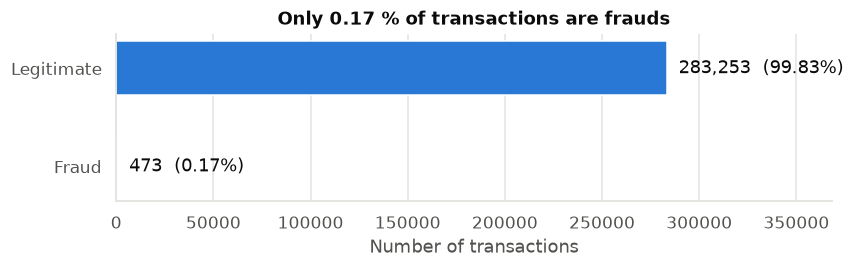

In [5]:
counts = df["Class"].value_counts().sort_index()
summary = pd.DataFrame({
    "transactions": counts,
    "share (%)": counts / counts.sum() * 100,
}, index=[0, 1]).rename(index={0: "Legitimate (0)", 1: "Fraud (1)"})
display(summary)
print(f"Imbalance ratio: 1 fraud for {counts[0] / counts[1]:,.0f} legitimate transactions")

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(["Fraud", "Legitimate"], [counts[1], counts[0]], color=[FRAUD_COLOR, LEGIT_COLOR], height=0.55)
for y_pos, value in zip([0, 1], [counts[1], counts[0]]):
    ax.text(value, y_pos, f"  {value:,}  ({value / counts.sum():.2%})", va="center", color="#0b0b0b")
ax.set_xlim(0, counts[0] * 1.3)
ax.set_xlabel("Number of transactions")
ax.set_title("Only 0.17 % of transactions are frauds")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "class_imbalance.png", bbox_inches="tight")
plt.show()

This is the **central problem of the project**. With fewer than 2 frauds per 1 000 transactions:

* **Accuracy is meaningless.** A "model" that answers *legitimate* for every transaction is right
  99.83 % of the time and catches zero fraud (demonstrated below).
* **Learning algorithms are biased toward the majority class.** Most classifiers minimise an
  overall error. Ignoring the frauds costs almost nothing in that error, so the model has little
  incentive to learn them.
* **There are very few fraud examples to learn from** (~470), so the fraud region of the feature
  space is sparsely described.

Resampling, which changes the class distribution of the *training* data, is one of the main
families of remedies. It is the subject of this project.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

X, y = df.drop(columns="Class"), df["Class"]
always_legit = DummyClassifier(strategy="most_frequent").fit(X, y).predict(X)
print(f"'Always legitimate' accuracy : {accuracy_score(y, always_legit):.4%}")
print(f"'Always legitimate' recall   : {recall_score(y, always_legit):.0%}  <- not a single fraud detected")

'Always legitimate' accuracy : 99.8333%
'Always legitimate' recall   : 0%  <- not a single fraud detected


We will therefore judge models with metrics that focus on the fraud class:

| Metric | Question it answers |
|---|---|
| **Recall** (sensitivity) | Of all frauds, how many did we catch? |
| **Precision** | Of all alerts raised, how many were really frauds? |
| **F1-score** | Harmonic mean of precision and recall |
| **PR-AUC** (average precision) | Precision/recall trade-off over *all* thresholds, our main metric. A random model scores ≈ 0.0017 here |
| **MCC** | Correlation between predictions and truth; robust to imbalance |
| ROC-AUC | Ranking quality; tends to look optimistic when negatives vastly outnumber positives |

## 3. When do frauds happen? (`Time`)

`Time` counts seconds from the first transaction, over 48 hours. Converting it to the **hour of the
day** (assuming the record starts at midnight) shows the daily cycle.

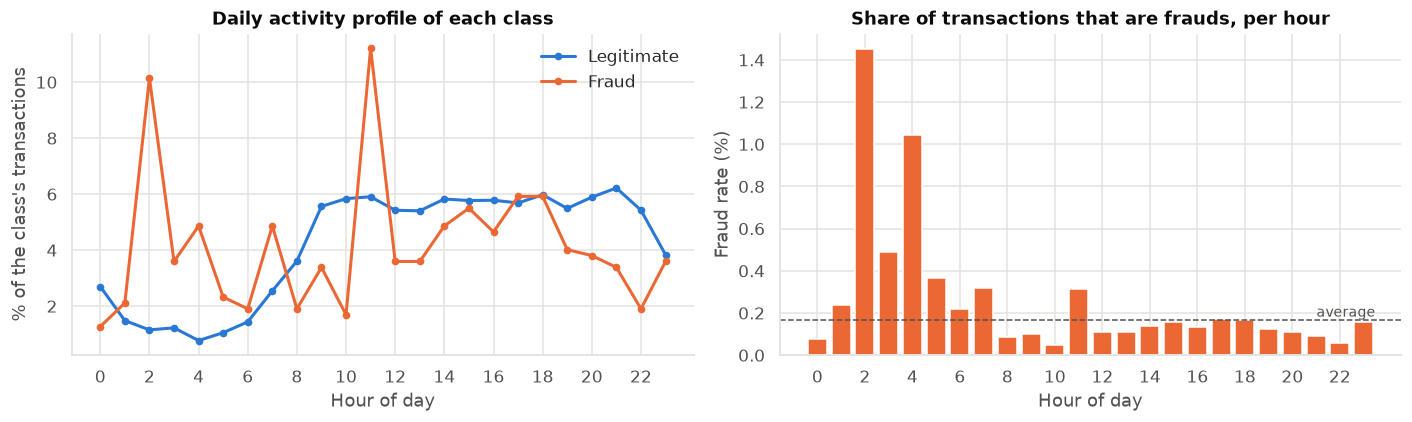

Hours with the highest fraud rate:
Time
2   1.4500
4   1.0400
3   0.4900


In [7]:
hour = (df["Time"] // 3600 % 24).astype(int)
per_hour = pd.crosstab(hour, df["Class"])
share = per_hour / per_hour.sum()             # distribution of each class over the day
fraud_rate = per_hour[1] / per_hour.sum(axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(share.index, share[0] * 100, color=LEGIT_COLOR, marker="o", ms=4, label="Legitimate")
axes[0].plot(share.index, share[1] * 100, color=FRAUD_COLOR, marker="o", ms=4, label="Fraud")
axes[0].set(xlabel="Hour of day", ylabel="% of the class's transactions",
            title="Daily activity profile of each class", xticks=range(0, 24, 2))
axes[0].legend()

axes[1].bar(fraud_rate.index, fraud_rate.values, color=FRAUD_COLOR, width=0.8)
axes[1].axhline(df["Class"].mean() * 100, color="#52514e", ls="--", lw=1)
axes[1].text(23.5, df["Class"].mean() * 100, " average", va="bottom", ha="right", color="#52514e", fontsize=9)
axes[1].set(xlabel="Hour of day", ylabel="Fraud rate (%)",
            title="Share of transactions that are frauds, per hour", xticks=range(0, 24, 2))
fig.tight_layout()
plt.show()

print("Hours with the highest fraud rate:")
print(fraud_rate.sort_values(ascending=False).head(3).round(2).to_string())

Legitimate activity follows a clear human rhythm: it is very low at night and peaks during the day.
Fraud activity is **much flatter**, so in the night hours a far larger proportion of the transactions
are frauds. Time of day therefore carries some signal, but frauds happen at all hours and `Time`
alone cannot separate the classes.

## 4. How much do fraudsters spend? (`Amount`)

,count,mean,std,min,25%,50%,75%,95%,max
Legitimate,"283,253.0000",88.4136,250.3790,0.0000,5.6700,22.0000,77.4600,365.0000,"25,691.1600"
Fraud,473.0000,123.8719,260.2110,0.0000,1.0000,9.8200,105.8900,655.8200,"2,125.8700"


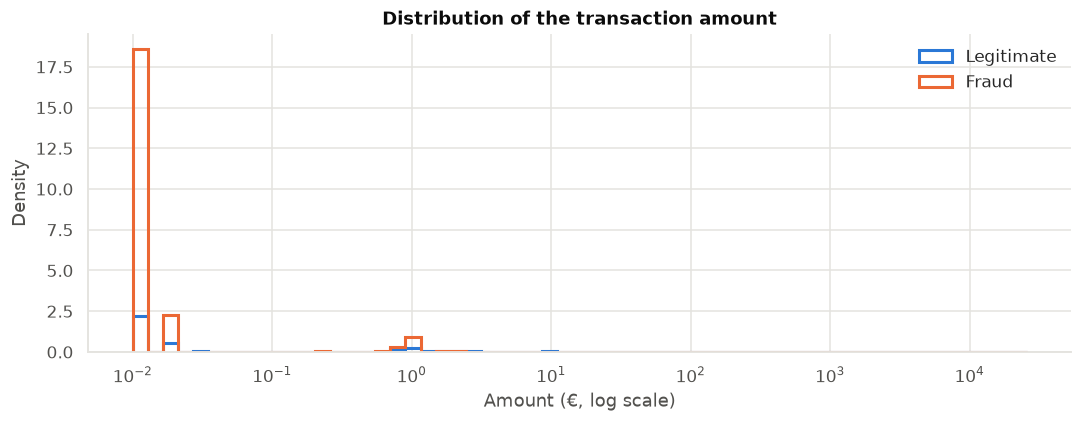

In [8]:
amount_stats = df.groupby("Class")["Amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95])
amount_stats.index = ["Legitimate", "Fraud"]
display(amount_stats)

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(-2, np.log10(df["Amount"].max() + 1), 60)
for cls, color, label in [(0, LEGIT_COLOR, "Legitimate"), (1, FRAUD_COLOR, "Fraud")]:
    ax.hist(df.loc[df["Class"] == cls, "Amount"] + 0.01, bins=bins, density=True,
            histtype="step", lw=2, color=color, label=label)
ax.set_xscale("log")
ax.set(xlabel="Amount (€, log scale)", ylabel="Density", title="Distribution of the transaction amount")
ax.legend()
fig.tight_layout()
plt.show()

* Amounts are **heavily right-skewed** for both classes, hence the log scale.
* Frauds are **not** especially large: their median is *lower* than for legitimate transactions,
  and the largest fraud is around 2 000 €. Many frauds are tiny amounts (≈ 1 €), consistent with
  fraudsters *testing* a stolen card before using it.
* The distributions overlap heavily, so `Amount` is a weak predictor on its own.

## 5. Which anonymised features separate the classes? (`V1…V28`)

To rank the 30 features we use the **Kolmogorov–Smirnov (KS) statistic**: the maximum distance between
the cumulative distributions of the feature in the fraud and legitimate classes
(0 = identical distributions, 1 = perfectly separated).

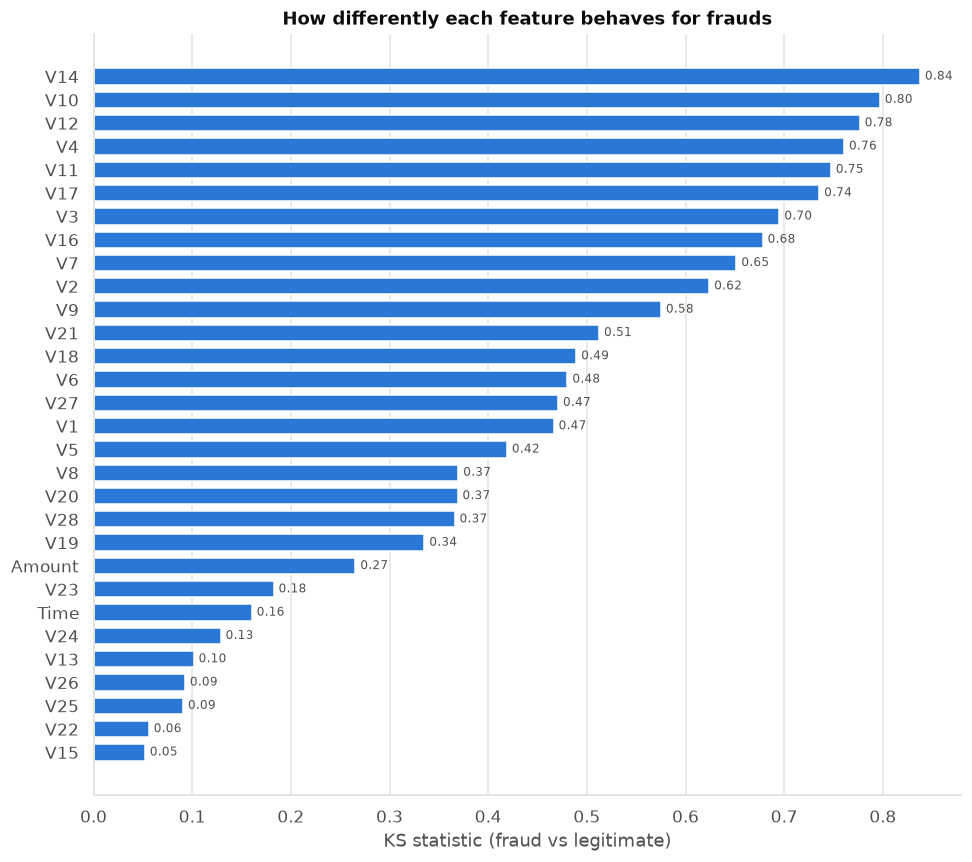

Most discriminative features: ['V14', 'V10', 'V12', 'V4', 'V11', 'V17']


In [9]:
from scipy.stats import ks_2samp

features = df.columns.drop("Class")
fraud, legit = df[df["Class"] == 1], df[df["Class"] == 0]
ks = pd.Series({f: ks_2samp(fraud[f], legit[f]).statistic for f in features}).sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(ks.index, ks.values, color=LEGIT_COLOR, height=0.7)
for i, v in enumerate(ks.values):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8, color="#52514e")
ax.set(xlabel="KS statistic (fraud vs legitimate)", title="How differently each feature behaves for frauds")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()
TOP = list(ks.sort_values(ascending=False).index[:6])
print("Most discriminative features:", TOP)

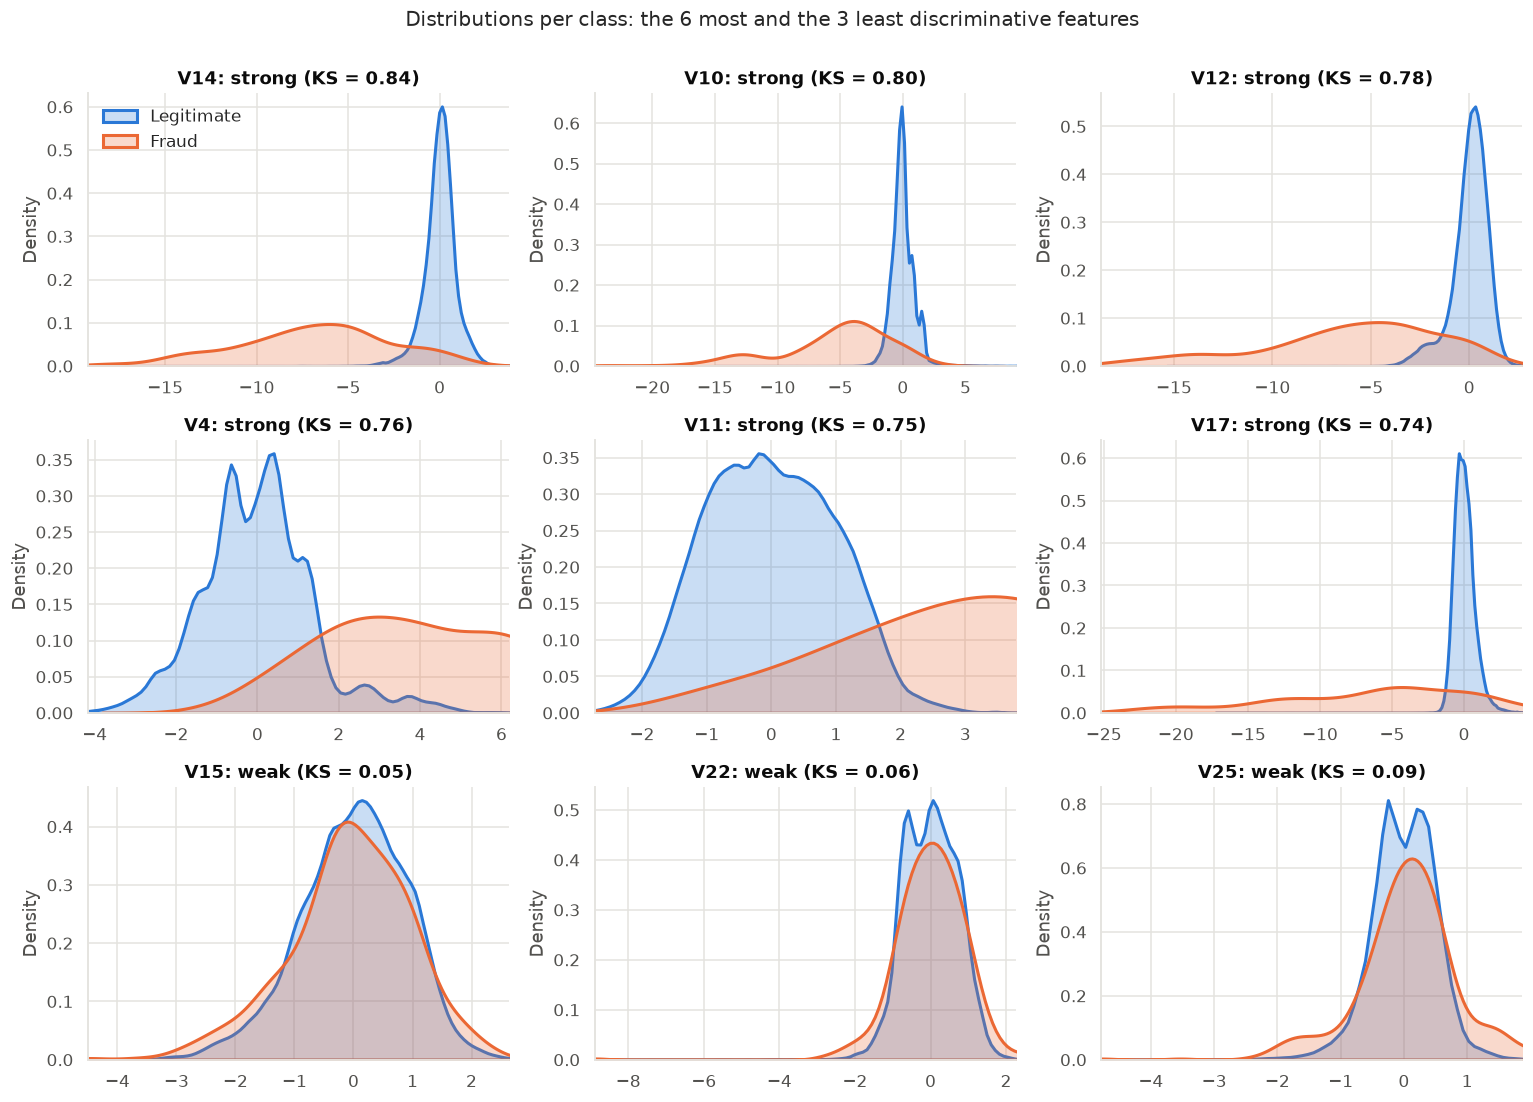

In [10]:
WEAK = list(ks.index[:3])
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, feat in zip(axes.flat, TOP + WEAK):
    for cls, color, label in [(0, LEGIT_COLOR, "Legitimate"), (1, FRAUD_COLOR, "Fraud")]:
        sns.kdeplot(df.loc[df["Class"] == cls, feat], ax=ax, color=color, fill=True, alpha=0.25,
                    lw=2, common_norm=False, label=label, warn_singular=False)
    strength = "strong" if feat in TOP else "weak"
    ax.set_title(f"{feat}: {strength} (KS = {ks[feat]:.2f})")
    ax.set_xlabel("")
    q = df[feat].quantile([0.001, 0.999])
    ax.set_xlim(min(q.iloc[0], fraud[feat].min()), q.iloc[1])
axes[0, 0].legend()
fig.suptitle("Distributions per class: the 6 most and the 3 least discriminative features", y=1.0, fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "feature_distributions.png", bbox_inches="tight")
plt.show()

For the strongest components (`V14`, `V10`, `V12`, `V4`, `V11`, `V17`…) the fraud distribution is clearly
**shifted** and much **wider** than the legitimate one. Frauds are, in a sense, *outliers* along these
directions, which is good news: the classes are partially separable. For the weakest features
(`V13`, `V15`, `V22`…) the two curves almost coincide.

Note also that frauds are **spread out**, not grouped in one compact cluster. This matters for
SMOTE-like techniques, which create new frauds by interpolating between existing ones.

## 6. Correlations, and how the imbalance hides them

Because `V1…V28` come from a PCA, they are uncorrelated with each other **on the full dataset**.
But with 99.8 % legitimate rows, the full-data correlation matrix mostly describes legitimate
transactions. Computing it on a **balanced random subsample** (all frauds + as many random
legitimate transactions) reveals how the features relate to fraud.

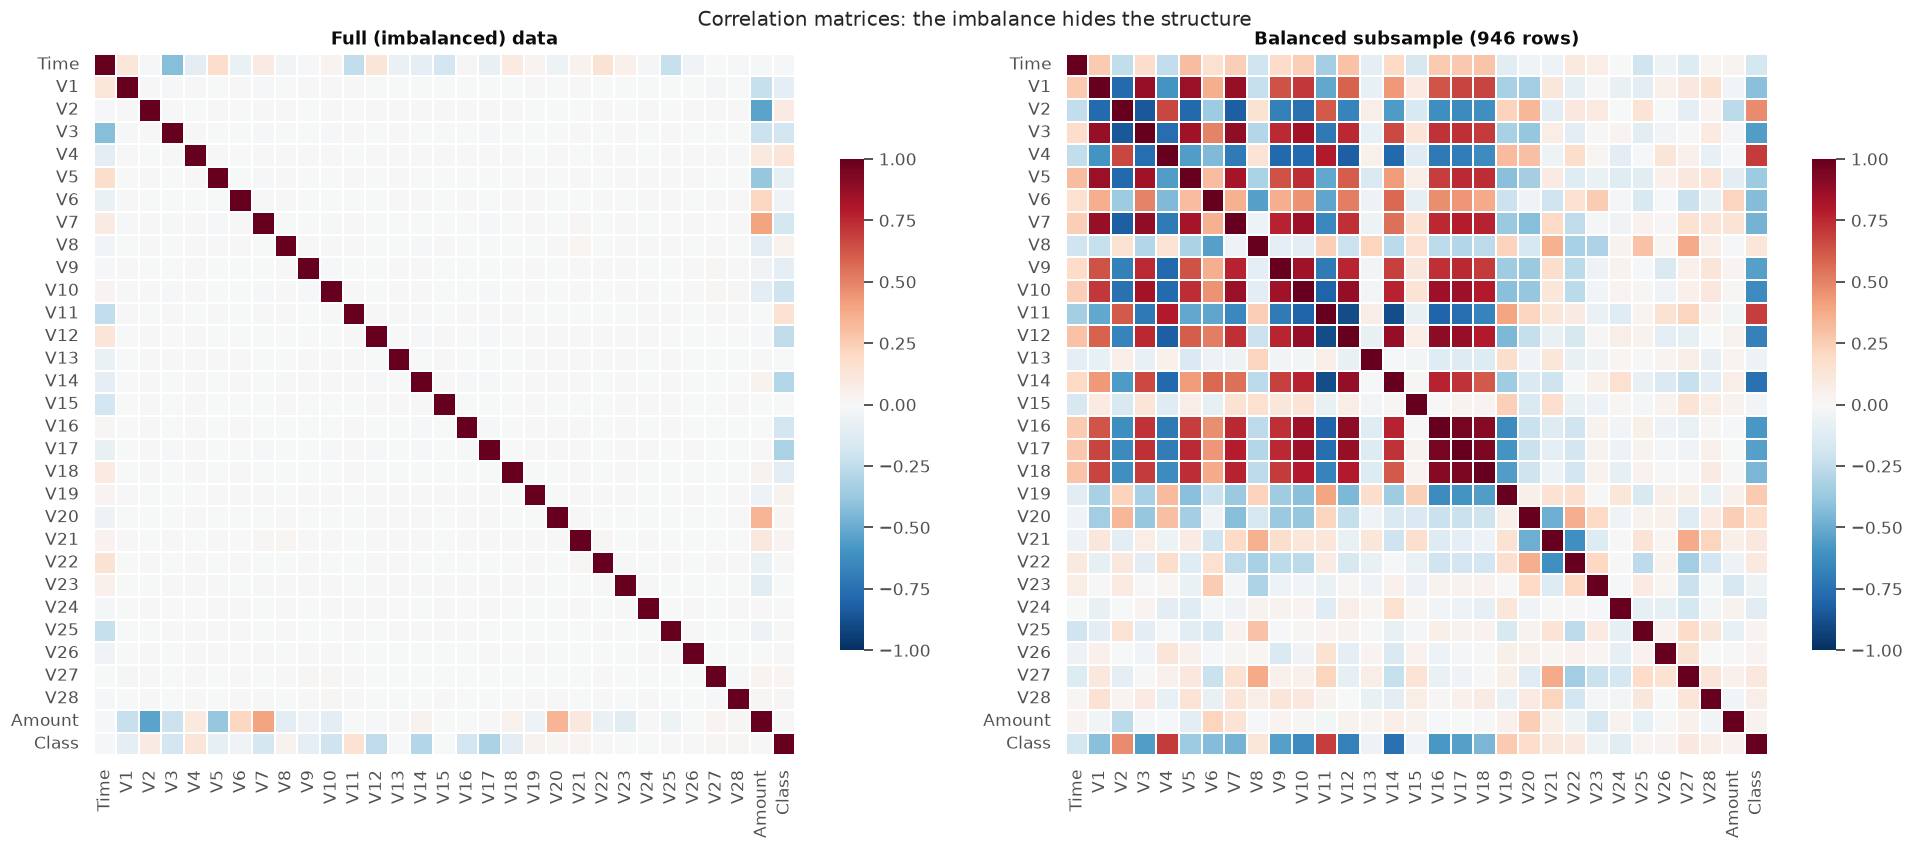

In [11]:
balanced = pd.concat([fraud, legit.sample(len(fraud), random_state=42)])

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, data, title in [(axes[0], df, "Full (imbalanced) data"),
                        (axes[1], balanced, f"Balanced subsample ({len(balanced):,} rows)")]:
    sns.heatmap(data.corr(), ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
                cbar_kws={"shrink": 0.7}, linewidths=0.2, linecolor="white")
    ax.set_title(title)
fig.suptitle("Correlation matrices: the imbalance hides the structure", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "correlation_matrices.png", bbox_inches="tight")
plt.show()

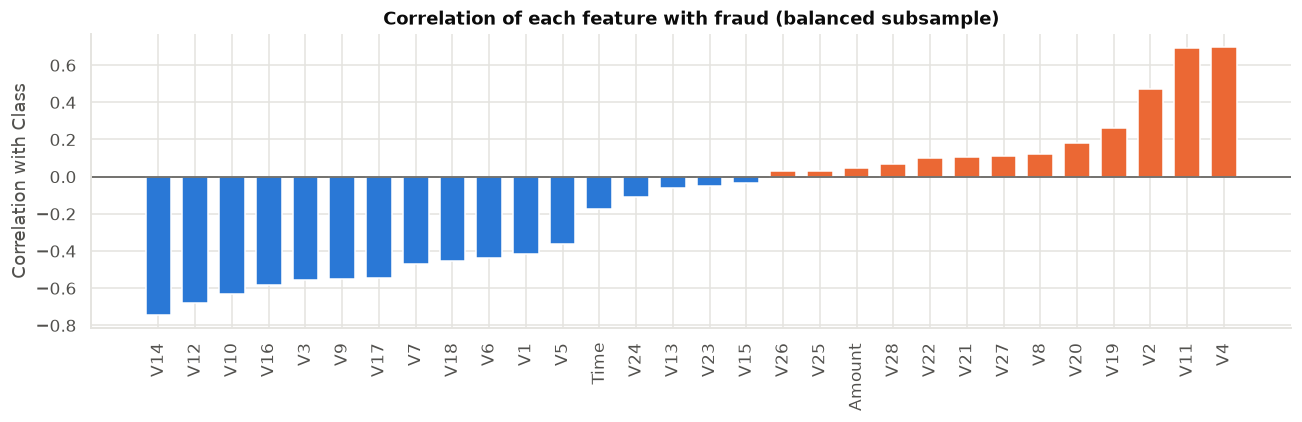

In [12]:
corr_with_class = balanced.corr()["Class"].drop("Class").sort_values()
fig, ax = plt.subplots(figsize=(12, 4))
colors = np.where(corr_with_class > 0, FRAUD_COLOR, LEGIT_COLOR)
ax.bar(corr_with_class.index, corr_with_class.values, color=colors, width=0.7)
ax.axhline(0, color="#52514e", lw=1)
ax.set(ylabel="Correlation with Class", title="Correlation of each feature with fraud (balanced subsample)")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()

On the full data the matrix is almost empty: only `Time` and `Amount` show correlations with some
components. On the balanced subsample, strong blocks appear:

* **Negatively correlated with fraud:** `V14`, `V12`, `V10`, `V16`, `V3`, `V9`, `V17`
  (the lower the value, the more likely the fraud),
* **Positively correlated with fraud:** `V4`, `V11`, `V2`, `V19`.

This is the same set of variables the KS ranking highlighted, and it shows concretely how the imbalance
*masks* the patterns we are looking for. That is the intuition behind rebalancing the training data.

## 7. Key takeaways

| Finding | Consequence for the rest of the project |
|---|---|
| ~1 000 duplicated rows | Removed, to avoid the same transaction appearing in train and test |
| **0.17 % frauds** (≈ 1 : 600) | Accuracy is useless → use PR-AUC, recall, precision, F1, MCC |
| `Time` and `Amount` on a different scale | Standardise features (inside the pipeline) before any distance-based step |
| Frauds are scattered outliers on `V14`, `V10`, `V12`, `V17`, `V4`… | Classes are partly separable; synthetic samples must stay in plausible regions |
| Very few frauds (~470) | Every fraud is precious: use **stratified** splits so each fold keeps some |

➡️ **Next:** [02 · Resampling techniques](02_resampling_techniques.ipynb) looks at how each technique
reshapes the training data.